# 01 — Exploración de datos

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MiltonCuervo/ham10000-skin-lesion-classification/blob/main/01_exploracion_de_datos.ipynb)

Ejecución local: abre Jupyter desde la carpeta del proyecto y selecciona **Python (HAM10000 local GPU)**. Ejecuta en orden 01–05. Los resultados se guardan localmente; no se monta Drive. En Colab, usa `/content` como carpeta del proyecto y ejecuta primero 01 y 02.


## 1. Rutas e importaciones

In [1]:
from pathlib import Path
import os, json, hashlib, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
PROJECT = Path.cwd().resolve()  # Abrir Jupyter desde la carpeta del proyecto.
DATA = PROJECT/'data'/'ham10000'
SPLITS = PROJECT/'data'/'splits'
CACHE = PROJECT/'data'/'processed_224'
SEED = 42
CLASSES = ['akiec','bcc','bkl','df','mel','nv','vasc']
POSITIVE = {'mel','bcc','akiec'}

## 2. Datos locales

Si los datos ya existen se utilizan directamente. La descarga es opcional para otro equipo o Colab; nunca escribas el token en una celda.

In [2]:
if not (DATA/'HAM10000_metadata.csv').exists():
    import sys, subprocess, getpass, zipfile
    subprocess.run([sys.executable,'-m','pip','install','--quiet','kaggle>=2.2.5'],check=True)
    cfg=PROJECT/'data'/'.kaggle'; cfg.mkdir(parents=True,exist_ok=True)
    env=os.environ.copy(); env['KAGGLE_CONFIG_DIR']=str(cfg)
    token=env.get('KAGGLE_API_TOKEN')
    if not token and not (cfg/'access_token').exists(): token=getpass.getpass('API token Kaggle (oculto): ').strip()
    if token: env['KAGGLE_API_TOKEN']=token
    DATA.mkdir(parents=True,exist_ok=True)
    try:
        command=[sys.executable,'-m','kaggle','datasets','download','-d','kmader/skin-cancer-mnist-ham10000','-p',str(DATA),'--quiet']
        result=subprocess.run(command,env=env,capture_output=True,text=True,errors='replace')
        if result.returncode: raise RuntimeError('Kaggle rechazó la descarga: revisa autenticación, conexión y permisos. No compartas tu token.')
        archive=DATA/'skin-cancer-mnist-ham10000.zip'
        with zipfile.ZipFile(archive) as z:
            if any(not (DATA/n).resolve().is_relative_to(DATA.resolve()) for n in z.namelist()): raise ValueError('Ruta ZIP no segura')
            z.extractall(DATA)
        archive.unlink()
    finally:
        env.pop('KAGGLE_API_TOKEN',None); token=None
print('Dataset:',DATA)

Dataset: C:\Users\Milton Cuervo\Documents\ham10000-skin-lesion-classification\data\ham10000


## 3. Metadatos y rutas

In [3]:
def index_images(root):
    index = {}
    for path in sorted(root.rglob('*.jpg')):
        if path.stem in index:
            other = index[path.stem]
            if hashlib.sha256(other.read_bytes()).digest() != hashlib.sha256(path.read_bytes()).digest():
                raise ValueError(f'Contenido diferente para {path.stem}: {other} / {path}')
        else:
            index[path.stem] = path
    return index

In [4]:
meta=pd.read_csv(DATA/'HAM10000_metadata.csv')
assert len(meta)==10015 and meta.image_id.is_unique
assert not meta[['image_id','lesion_id','dx']].isna().any().any()
paths=index_images(DATA); meta['path']=meta.image_id.map(paths)
assert meta.path.notna().all()
print(len(meta),'imágenes;',meta.lesion_id.nunique(),'lesiones')
display(meta.isna().sum().to_frame('Valores ausentes'))
display(meta.dx.value_counts().to_frame('Imágenes'))

10015 imágenes; 7470 lesiones


,Valores ausentes
lesion_id,0
image_id,0
dx,0
dx_type,0
age,57
sex,0
localization,0
path,0


,Imágenes
dx,
nv,6705
mel,1113
bkl,1099
bcc,514
akiec,327
vasc,142
df,115


## 4. Desbalance, lesiones e imágenes

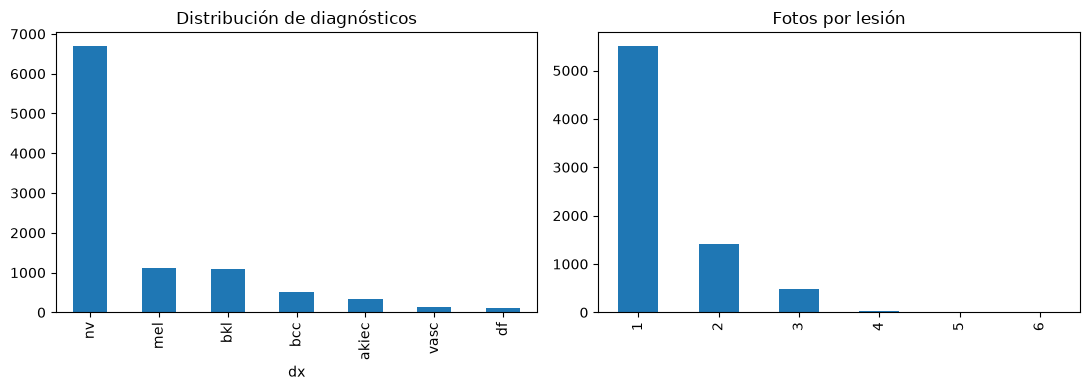

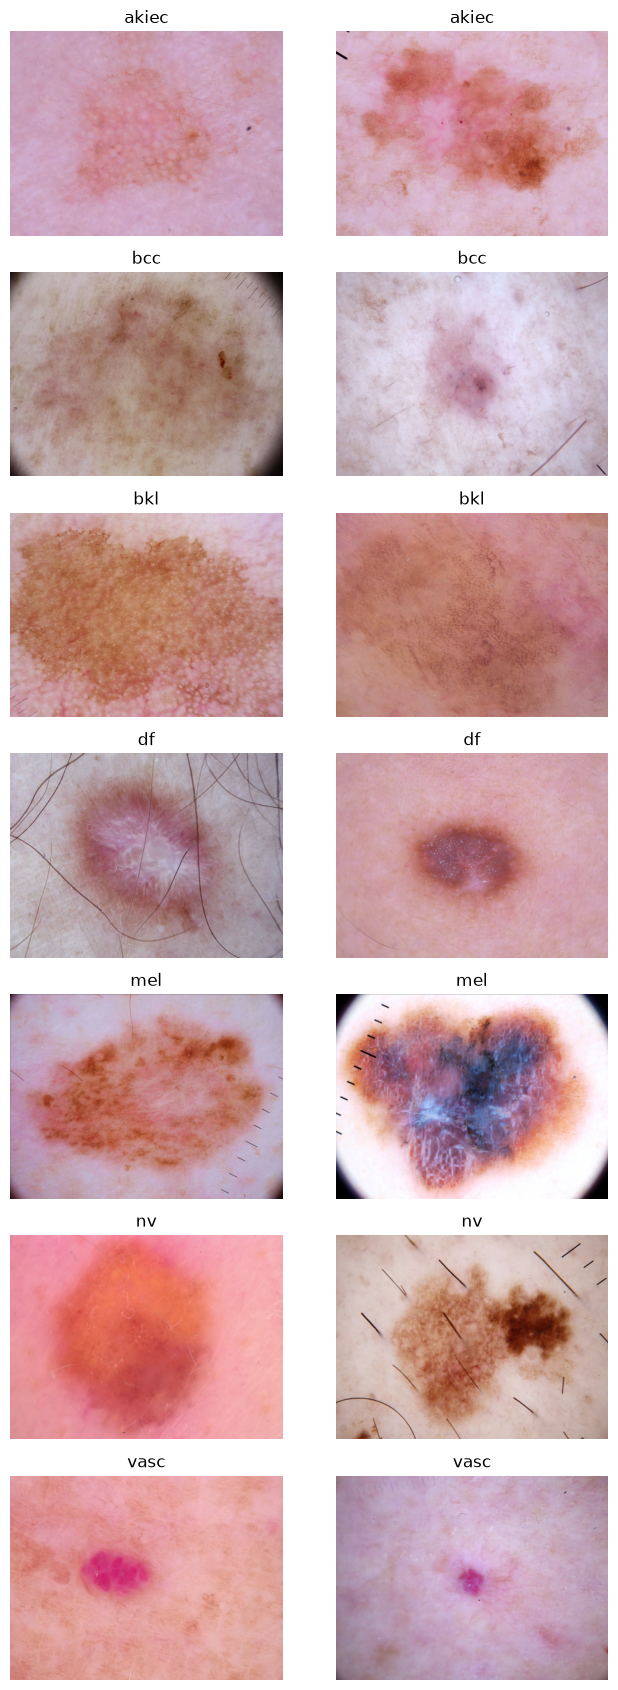

In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
meta.dx.value_counts().plot.bar(ax=axes[0],title='Distribución de diagnósticos')
meta.groupby('lesion_id').size().value_counts().sort_index().plot.bar(ax=axes[1],title='Fotos por lesión')
fig.tight_layout(); plt.show()
fig,axes=plt.subplots(7,2,figsize=(7,17))
for i,diagnosis in enumerate(CLASSES):
    for j,row in enumerate(meta[meta.dx==diagnosis].sample(2,random_state=SEED).itertuples()):
        with Image.open(row.path) as image: axes[i,j].imshow(image.copy())
        axes[i,j].set_title(diagnosis); axes[i,j].axis('off')
fig.tight_layout(); plt.show()

HAM10000: Tschandl, Rosendahl y Kittler (2018), DOI 10.1038/sdata.2018.161. La copia de Kaggle utilizada declara CC-BY-NC-SA-4.0. Uso académico no comercial; las métricas requieren experimentos reales.